### Tests of Tang Farfield model

In [1]:
# To get the parent path for the notebook
import sys
import os

parent_dir = os.path.abspath(os.path.join(os.getcwd(), '..'))

if parent_dir not in sys.path:
    sys.path.insert(0, parent_dir)

In [2]:
%matplotlib widget

import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import c, pi

import plotly.io as pio
pio.renderers.default = 'notebook_connected' # 'browser' for avoid error but shown in the browser
import plotly.graph_objects as go

from utils.utils import *
from components.ris import RIS
from components.antenna import Antenna
from channels.tx_ris_rx_channel import tx_ris_rx_channel

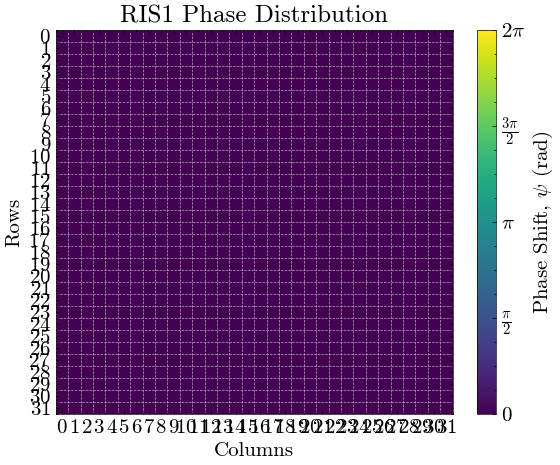

In [14]:
# Create RIS
f = 28e9
lam = c/f

ris = RIS(center=[0,0,0],boresight='z',Ncol=32,Nrow=32,delta_h=lam/2,delta_v=lam/2,dx=lam/2,dy=lam/2,fc=f,radiation_factor=1,phase_shifts_dict={"0": 0,"1": pi},att_dict={"0": 1,"1": 1})

ris.plot_phase_dist()

In [18]:
area_ris = ris.Ncol * ris.Nrow * (ris.dx * ris.dy)
d_ff = 4  * area_ris / lam # Because is an square array with same height and width
print(f"Distance for farfield: {d_ff} m")

Distance for farfield: 10.963838464 m


In [19]:
# Create antennas and channel
tx_pos = sph2cart([12,0,0])
rx_pos = sph2cart([12,180,30])

tx_antenna = Antenna(tx_pos,0)
rx_antenna = Antenna(rx_pos,0)

channel_gen = tx_ris_rx_channel(tx_antenna=tx_antenna,rx_antenna=rx_antenna,ris=ris,model='Tang_general')
channel_ff = tx_ris_rx_channel(tx_antenna=tx_antenna,rx_antenna=rx_antenna,ris=ris,model='Tang_farfield')

In [20]:
channel_gen.optimize(mode='cont')
bf_gen = channel_gen.phase_bf_multrx(rx_positions=rx_pos)

channel_ff.optimize(mode='cont')
bf_ff = channel_ff.phase_bf_multrx(rx_positions=rx_pos)

max_bf = (ris.Nrow * ris.Ncol)**2

print(bf_gen / max_bf)
print(bf_ff / max_bf)


[1.]
[0.98008138]


In [22]:
pg_gen = channel_gen.path_gain_multrx(rx_positions=rx_pos)
pg_ff = channel_ff.path_gain_multrx(rx_positions=rx_pos)

print(10 * np.log10(pg_gen))
print(10 * np.log10(pg_ff))

[-96.42514779]
[-96.51221327]


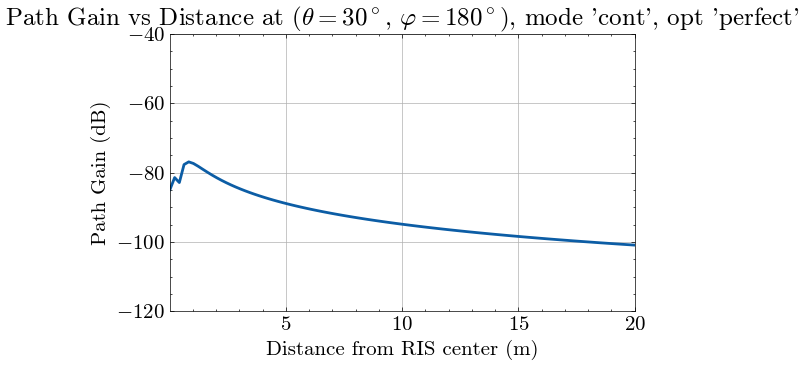

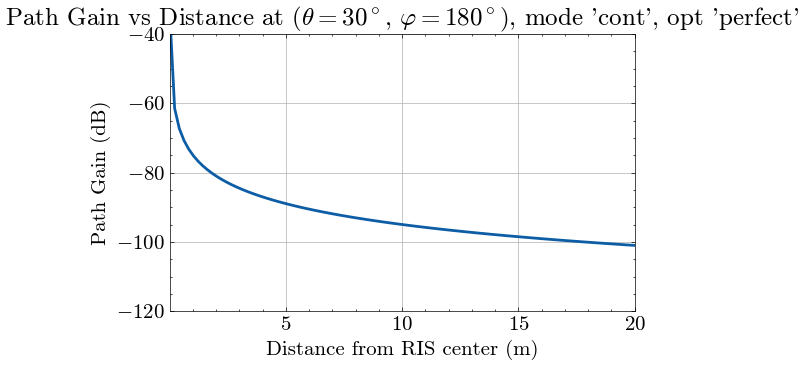

In [25]:
channel_gen.plot_path_gain_dist(phi_deg=180, theta_deg=30, r1=0.01, r2=20, Nr=100, vmin=-120, vmax=-40)

channel_ff.plot_path_gain_dist(phi_deg=180, theta_deg=30, r1=0.01, r2=20, Nr=100, vmin=-120, vmax=-40)